**[🏠 Course Home](../README.md) | 📖 Conceptual Companion: [Bayesian Mean](../conceptual/sheet_calculating_a_mean_in_a_bayesian_world.ipynb) | 🔵 R Track: [Bayesian Mean](../r/sheet_calculating_a_mean_in_a_bayesian_world.ipynb) | ↩️ Previous: [Frequentist Mean](sheet_calculating_a_mean_in_a_frequentist_world.ipynb) | ⏭️ Next: [Two-Sample Comparison](sheet_t_test_frequentist_vs_bayesian.ipynb)**

---

# Sheet: Calculating a Mean in a Bayesian World
### *Priors, Likelihoods, The Normal Conjugate Tug-of-War, MCMC Sampling, and Posterior Predictive Inference*

In the frequentist paradigm, estimating a population mean $\mu$ requires imagining infinite hypothetical repetitions of an experiment to evaluate how a formula ($\bar{X}$) behaves, while treating the parameter $\mu$ as a silent, non-random constant.

In the **Bayesian paradigm**, the philosophical perspective flips completely:
* **The Observed Data is Fixed and Known**: We condition directly on the specific data sample $y$ we collected.
* **The Parameter is Uncertain**: We treat the population mean $\mu$ as an unobserved quantity characterized by a **probability distribution** expressing our state of knowledge.
* **Inference as Logical Updating**: We use **Bayes' Theorem** to combine prior domain knowledge $p(\mu)$ with the data likelihood $p(y \mid \mu)$ to produce the **Posterior Distribution** $p(\mu \mid y)$.
* **Direct Probabilistic Answers**: Instead of cryptic $p$-values and 100-universe confidence procedures, we answer business questions directly:
  * *"What is the probability that mean latency is under 140 ms?"* $\rightarrow P(\mu \le 140 \mid y)$.
  * *"What is the 95% Highest Density Interval?"* $\rightarrow$ The narrowest interval that contains 95% of our posterior belief.
  * *"What will tomorrow's latency look like?"* $\rightarrow$ The **Posterior Predictive Distribution** $p(\tilde{y} \mid y)$.

This sheet provides an end-to-end practical walkthrough of estimating a mean in a Bayesian world—from analytical Gaussian conjugacy to MCMC simulation, decision theory, and robust estimation under heavy-tailed outliers.


## 🧭 Executive Summary: Frequentist vs. Bayesian Mean Estimation at a Glance

| Feature / Dimension | Frequentist Paradigm | Bayesian Paradigm |
| :--- | :--- | :--- |
| **Core Epistemology** | Parameters ($\mu$) are fixed, immutable constants of nature. Probability represents **long-run frequencies** over infinite hypothetical repetitions. | Parameters ($\mu$) are unobserved random variables. Probability represents **degrees of belief / plausibility** conditioned on evidence. |
| **Primary Output** | A single point estimate $\bar{x}$, a standard error $SE$, and a 95% Confidence Interval. | A complete **posterior probability distribution** $p(\mu \mid y)$ capturing all remaining uncertainty. |
| **Point Estimate** | Arithmetic sample mean $\bar{x} = \frac{1}{n}\sum x_i$ (MVUE & MLE). | Depends on the chosen **loss function**: Posterior Mean (squared error), Posterior Median (absolute error), or MAP (0-1 loss). |
| **Interval Meaning** | **95% Confidence Interval**: In 95% of hypothetical repeated identical experiments, the calculated interval covers $\mu$. | **95% Credible Interval (HDI)**: Given the prior and observed data, there is a 95% probability that the true parameter $\mu$ lies inside this exact interval. |
| **Prior Knowledge** | Forbidden / impossible to formally incorporate; all inference must flow strictly from the current sample. | **Natural & explicit**: Prior domain knowledge $p(\mu)$ acts as regularizing evidence, preventing overfitting in small samples. |
| **Small Sample Behavior** | Fragile when $n$ is small ($n < 5$); intervals explode in width or fail under non-normality. | Well-calibrated; informative priors stabilize estimates (e.g. cold-start microservice telemetry). |
| **Handling Outliers** | Arithmetic mean has a 0% breakdown point; single outlier pulls $\bar{x}$ dramatically. | **Robust modeling**: Swap Gaussian likelihood for Student-$t$ likelihood to automatically down-weight outliers. |
| **Future Predictions** | Plug-in prediction intervals substitute point estimates $(\bar{x}, s)$, understating parameter uncertainty. | **Posterior Predictive Distribution**: Integrates over all parameter uncertainty: $p(\tilde{y} \mid y) = \int p(\tilde{y} \mid \mu, \sigma) p(\mu, \sigma \mid y) d\mu d\sigma$. |
| **Decision Rules** | Arbitrary binary threshold ($p < 0.05$); cannot accept the null hypothesis. | Continuous decision analysis via **Region of Practical Equivalence (ROPE)** and direct risk calculation. |


## Part 1: The Production Scenario & Observed Data

### 1.1 The Engineering Context
We examine the exact same production microservice benchmark as our frequentist worksheet to ensure direct comparability:
* We collect $n = 35$ execution latency measurements (in milliseconds) from a core transaction service.
* Ground truth parameters (unknown in production): $\mu = 142.5\text{ ms}$, $\sigma = 28.0\text{ ms}$.
* **Prior Engineering Knowledge**: Historical telemetry from previous versions of the service suggests that mean latency typically hovers around $\mu_0 = 150.0\text{ ms}$ with an uncertainty scale $\sigma_0 = 20.0\text{ ms}$.

Let's load the libraries, generate the observed dataset, and inspect our prior beliefs.


In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set random seed for exact reproducibility
np.random.seed(42)

# Ground truth population parameters (hidden from engineer)
true_mu = 142.5    # True population mean latency (ms)
true_sigma = 28.0  # True population standard deviation (ms)

# Sample size
n = 35

# Observed production sample data (same data as frequentist sheet)
y = np.random.normal(loc=true_mu, scale=true_sigma, size=n)

# Prior parameters from historical service telemetry
prior_mu = 150.0       # Prior expected mean latency (ms)
prior_sigma = 20.0     # Prior standard deviation (uncertainty about μ)

print("=" * 68)
print("  BAYESIAN DATA & PRIOR SETUP")
print("=" * 68)
print(f"Sample Size (n)                   : {n} requests")
print(f"Sample Mean (ȳ)                   : {np.mean(y):.2f} ms")
print(f"Sample Standard Deviation (s)     : {np.std(y, ddof=1):.2f} ms")
print(f"Standard Error of Mean (s / √n)   : {np.std(y, ddof=1) / np.sqrt(n):.2f} ms")
print("-" * 68)
print(f"Prior Mean (μ0)                   : {prior_mu:.2f} ms")
print(f"Prior Standard Deviation (σ0)     : {prior_sigma:.2f} ms")
print("=" * 68)


  BAYESIAN DATA & PRIOR SETUP
Sample Size (n)                   : 35 requests
Sample Mean (ȳ)                   : 138.79 ms
Sample Standard Deviation (s)     : 26.09 ms
Standard Error of Mean (s / √n)   : 4.41 ms
--------------------------------------------------------------------
Prior Mean (μ0)                   : 150.00 ms
Prior Standard Deviation (σ0)     : 20.00 ms


---

## Part 2: Route 1 — Exact Analytical Conjugacy (The Gaussian Tug-of-War)

When we assume the measurement noise scale $\sigma$ is known (or approximated by sample standard deviation $s$), estimating a Gaussian mean with a Gaussian prior is an **exact conjugate model**.

### 2.1 Bayes' Theorem for Continuous Parameters
$$p(\mu \mid y) = \frac{p(y \mid \mu) \cdot p(\mu)}{p(y)} \propto p(y \mid \mu) \cdot p(\mu)$$
* **Prior**: $p(\mu) = \mathcal{N}(\mu_0, \sigma_0^2)$
* **Likelihood**: $p(y \mid \mu) = \prod_{i=1}^n \mathcal{N}(y_i \mid \mu, \sigma^2) \propto \mathcal{N}\left(\bar{y} \;\middle|\; \mu, \frac{\sigma^2}{n}\right)$

### 2.2 Precision as Voting Power ($\tau = 1 / \sigma^2$)
In Bayesian statistics, **precision** ($\tau$) is the reciprocal of variance:
$$\tau_0 = \frac{1}{\sigma_0^2} \quad (\text{Prior Precision}), \qquad \tau_n = \frac{n}{\sigma^2} \quad (\text{Data Precision})$$

Because precision measures information density, the posterior precision is simply the **direct sum of precisions**:
$$\tau_{\text{post}} = \tau_0 + \tau_n \implies \sigma_{\text{post}}^2 = \frac{1}{\tau_0 + \tau_n}$$

The posterior mean $\mu_{\text{post}}$ is a precision-weighted compromise (a "Tug-of-War"):
$$\mu_{\text{post}} = \frac{\tau_0 \mu_0 + \tau_n \bar{y}}{\tau_0 + \tau_n} = \left(\frac{\tau_0}{\tau_{\text{post}}}\right)\mu_0 + \left(\frac{\tau_n}{\tau_{\text{post}}}\right)\bar{y}$$

> [!IMPORTANT]
> **The Two Extreme Limits**:
> 1. **Zero Prior Knowledge (Flat / Non-Informative Prior, $\sigma_0 \to \infty \implies \tau_0 \to 0$)**:
>    $$\mu_{\text{post}} \to \bar{y}, \qquad \sigma_{\text{post}} \to \frac{\sigma}{\sqrt{n}} = SE$$
>    Under an uninformative prior, the Bayesian posterior matches the frequentist sampling distribution mathematically, but with a vastly superior epistemological interpretation: you can now legitimately say there is a 95% probability $\mu$ is in the interval!
> 2. **Infinite Data ($n \to \infty \implies \tau_n \to \infty$)**:
>    The data completely overwhelms the prior, regardless of prior strength.


In [2]:
# Analytical Gaussian Conjugate Updating
sigma_known = np.std(y, ddof=1) # Approximated by sample standard deviation

# 1. Informative Prior (Historical deployment: mu_0 = 150, sigma_0 = 20)
tau_0 = 1.0 / (prior_sigma ** 2)
tau_data = n / (sigma_known ** 2)

tau_post = tau_0 + tau_data
post_var = 1.0 / tau_post
post_std = np.sqrt(post_var)
post_mean = (tau_0 * prior_mu + tau_data * np.mean(y)) / tau_post

# Weights in the tug-of-war
w_prior = tau_0 / tau_post
w_data = tau_data / tau_post

# 2. Weakly Informative Prior (sigma_0 = 100)
tau_weak = 1.0 / (100.0 ** 2)
tau_post_weak = tau_weak + tau_data
post_std_weak = np.sqrt(1.0 / tau_post_weak)
post_mean_weak = (tau_weak * prior_mu + tau_data * np.mean(y)) / tau_post_weak

# 3. Flat / Uninformative Prior (tau_0 -> 0)
post_mean_flat = np.mean(y)
post_std_flat = sigma_known / np.sqrt(n)

# 95% Credible Intervals (Analytical Gaussian)
ci_inform = (post_mean - 1.96 * post_std, post_mean + 1.96 * post_std)
ci_weak = (post_mean_weak - 1.96 * post_std_weak, post_mean_weak + 1.96 * post_std_weak)
ci_flat = (post_mean_flat - 1.96 * post_std_flat, post_mean_flat + 1.96 * post_std_flat)

print("=" * 72)
print("  ANALYTICAL NORMAL-NORMAL CONJUGATE UPDATING")
print("=" * 72)
print(f"Prior Precision (τ0)              : {tau_0:.6f} (Weight: {w_prior:.1%})")
print(f"Data Precision (τn = n/σ²)        : {tau_data:.6f} (Weight: {w_data:.1%})")
print(f"Posterior Precision (τ_post)      : {tau_post:.6f}")
print("-" * 72)
print(f"1. Informative Prior Posterior     : μ = {post_mean:.2f} ms, σ = {post_std:.2f} ms | 95% CI: [{ci_inform[0]:.2f}, {ci_inform[1]:.2f}]")
print(f"2. Weakly Informative Posterior    : μ = {post_mean_weak:.2f} ms, σ = {post_std_weak:.2f} ms | 95% CI: [{ci_weak[0]:.2f}, {ci_weak[1]:.2f}]")
print(f"3. Flat Prior Posterior (SE limit) : μ = {post_mean_flat:.2f} ms, σ = {post_std_flat:.2f} ms | 95% CI: [{ci_flat[0]:.2f}, {ci_flat[1]:.2f}]")
print("=" * 72)


  ANALYTICAL NORMAL-NORMAL CONJUGATE UPDATING
Prior Precision (τ0)              : 0.002500 (Weight: 4.6%)
Data Precision (τn = n/σ²)        : 0.051409 (Weight: 95.4%)
Posterior Precision (τ_post)      : 0.053909
------------------------------------------------------------------------
1. Informative Prior Posterior     : μ = 139.31 ms, σ = 4.31 ms | 95% CI: [130.86, 147.75]
2. Weakly Informative Posterior    : μ = 138.81 ms, σ = 4.41 ms | 95% CI: [130.17, 147.44]
3. Flat Prior Posterior (SE limit) : μ = 138.79 ms, σ = 4.41 ms | 95% CI: [130.14, 147.43]


---

## Part 3: Unknown Variance — The Joint Posterior $p(\mu, \sigma \mid y)$ & MCMC Sampling

In real systems, the noise scale $\sigma$ is **never known exactly**. We must estimate $\mu$ and $\sigma$ simultaneously as joint parameters $\theta = (\mu, \sigma)$.

### 3.1 The Joint Model
* **Parameter Space**: $\mu \in (-\infty, \infty), \quad \sigma \in (0, \infty)$ (parametrized in log-space: $\log\sigma \in (-\infty, \infty)$)
* **Priors**:
  $$\mu \sim \mathcal{N}(\mu_0, \sigma_0^2), \qquad \log\sigma \sim \mathcal{N}\left(\log s, 1.0^2\right)$$
* **Likelihood**:
  $$p(y \mid \mu, \sigma) = \prod_{i=1}^n \frac{1}{\sqrt{2\pi}\sigma} \exp\left(-\frac{(y_i - \mu)^2}{2\sigma^2}\right)$$
* **Joint Log-Posterior**:
  $$\ln p(\mu, \log\sigma \mid y) = \ln p(\mu) + \ln p(\log\sigma) + \sum_{i=1}^n \ln \mathcal{N}(y_i \mid \mu, \sigma) + \text{const}$$

We implement the **Metropolis-Hastings algorithm** from scratch to sample 30,000 draws from the true joint posterior.


In [3]:
# MCMC Sampling: Metropolis-Hastings for (mu, log_sigma)
def log_joint_posterior(params):
    mu_curr, log_s_curr = params
    s_curr = np.exp(log_s_curr)
    
    # 1. Log-Priors
    lp_mu = stats.norm.logpdf(mu_curr, loc=prior_mu, scale=prior_sigma)
    lp_sigma = stats.norm.logpdf(log_s_curr, loc=np.log(np.std(y, ddof=1)), scale=1.0)
    
    # 2. Log-Likelihood
    ll = np.sum(stats.norm.logpdf(y, loc=mu_curr, scale=s_curr))
    
    return lp_mu + lp_sigma + ll

# MCMC Setup
np.random.seed(42)
n_samples = 30000
burn_in = 5000

# Initialize at sample statistics
current_params = np.array([np.mean(y), np.log(np.std(y, ddof=1))])
current_log_prob = log_joint_posterior(current_params)

proposal_sds = np.array([1.2, 0.08])
chain = np.zeros((n_samples, 2))
accepted = 0

for i in range(n_samples):
    candidate = current_params + np.random.normal(0, proposal_sds)
    candidate_log_prob = log_joint_posterior(candidate)
    
    # Metropolis acceptance ratio in log-space
    log_alpha = candidate_log_prob - current_log_prob
    if np.log(np.random.uniform(0, 1)) < log_alpha:
        current_params = candidate
        current_log_prob = candidate_log_prob
        accepted += 1
        
    chain[i] = current_params

# Discard burn-in
samples_mu = chain[burn_in:, 0]
samples_sigma = np.exp(chain[burn_in:, 1])

acceptance_rate = accepted / n_samples
print("=" * 68)
print("  METROPOLIS-HASTINGS MCMC DIAGNOSTICS")
print("=" * 68)
print(f"Total Iterations                  : {n_samples:,}")
print(f"Burn-in Discarded                 : {burn_in:,}")
print(f"Retained Posterior Draws          : {len(samples_mu):,}")
print(f"Metropolis Acceptance Rate        : {acceptance_rate:.1%} (Target: 20-50%)")
print(f"Posterior Mean of μ               : {np.mean(samples_mu):.2f} ms")
print(f"Posterior Std Dev of μ            : {np.std(samples_mu):.2f} ms")
print(f"Posterior Mean of σ               : {np.mean(samples_sigma):.2f} ms")
print("=" * 68)


  METROPOLIS-HASTINGS MCMC DIAGNOSTICS
Total Iterations                  : 30,000
Burn-in Discarded                 : 5,000
Retained Posterior Draws          : 25,000
Metropolis Acceptance Rate        : 76.2% (Target: 20-50%)
Posterior Mean of μ               : 139.68 ms
Posterior Std Dev of μ            : 4.69 ms
Posterior Mean of σ               : 26.87 ms


---

## Part 4: Bayesian Decision Analysis — Point Estimates, HDI, and ROPE

In Bayesian analysis, the posterior distribution is not just a summary—it is an **engine for making optimal decisions under uncertainty**.

### 4.1 Optimal Point Estimates via Loss Functions
Frequentists default to the sample mean $\bar{x}$. In Bayesian decision theory, the "best" point estimate $\hat{\theta}$ depends explicitly on the cost of being wrong (the **Loss Function**):
1. **Squared Error Loss** $L(\theta, \hat{\theta}) = (\theta - \hat{\theta})^2$:
   Minimizing expected loss yields the **Posterior Mean**:
   $$\hat{\theta} = \mathbb{E}[\mu \mid y] = \frac{1}{S}\sum_{s=1}^S \mu^{(s)}$$
2. **Absolute Error Loss** $L(\theta, \hat{\theta}) = |\theta - \hat{\theta}|$:
   Minimizing expected loss yields the **Posterior Median**:
   $$\hat{\theta} = \text{Median}(\mu \mid y)$$
3. **0-1 Loss** (All errors equally penalized):
   Yields the **Maximum A Posteriori (MAP)** mode.

### 4.2 The 95% Highest Density Interval (HDI)
Unlike an equal-tailed credible interval (which cuts 2.5% off each tail), the **Highest Density Interval (HDI)** possesses two unique mathematical properties:
1. Every point inside the HDI has a **higher posterior probability density** than any point outside.
2. It is the **narrowest possible interval** containing 95% of the posterior mass.

### 4.3 Practical Decision Making: Direct Probability & ROPE
Suppose our Service Level Objective (SLO) requires that mean latency be no greater than $145.0\text{ ms}$.
In the frequentist world, we can only compute a convoluted $p$-value under a hypothetical null.
In the Bayesian world, we ask the question directly:
$$P(\mu \le 145.0\text{ ms} \mid y) = \frac{1}{S}\sum_{s=1}^S \mathbb{I}\left(\mu^{(s)} \le 145.0\right)$$


In [4]:
# Compute Bayesian Point Estimates & 95% Highest Density Interval (HDI)
def compute_hdi(samples, cred_mass=0.95):
    sorted_s = np.sort(samples)
    n_samples = len(sorted_s)
    ci_index = int(np.floor(cred_mass * n_samples))
    n_ci = n_samples - ci_index
    ci_widths = sorted_s[ci_index:] - sorted_s[:n_ci]
    min_idx = np.argmin(ci_widths)
    return sorted_s[min_idx], sorted_s[min_idx + ci_index]

# 1. Point Estimates
bayes_mean = np.mean(samples_mu)
bayes_median = np.median(samples_mu)
# Approximate MAP from KDE mode
kde_mu = stats.gaussian_kde(samples_mu)
mu_grid = np.linspace(np.min(samples_mu), np.max(samples_mu), 1000)
bayes_map = mu_grid[np.argmax(kde_mu(mu_grid))]

# 2. Intervals
hdi_low, hdi_high = compute_hdi(samples_mu, cred_mass=0.95)
eti_low, eti_high = np.percentile(samples_mu, [2.5, 97.5])

# 3. Direct SLO Probability Statement: P(μ <= 145.0 ms)
slo_threshold = 145.0
prob_meets_slo = np.mean(samples_mu <= slo_threshold)

print("=" * 68)
print("  BAYESIAN POINT ESTIMATES, INTERVALS & SLO DECISION")
print("=" * 68)
print(f"Posterior Mean (Squared Loss)     : {bayes_mean:.2f} ms")
print(f"Posterior Median (Absolute Loss)  : {bayes_median:.2f} ms")
print(f"MAP Mode (0-1 Loss)               : {bayes_map:.2f} ms")
print("-" * 68)
print(f"95% Highest Density Interval (HDI): [{hdi_low:.2f}, {hdi_high:.2f}] ms (Width: {hdi_high - hdi_low:.2f} ms)")
print(f"95% Equal-Tailed Interval (ETI)   : [{eti_low:.2f}, {eti_high:.2f}] ms (Width: {eti_high - eti_low:.2f} ms)")
print("-" * 68)
print(f"SLO Target Threshold              : μ <= {slo_threshold:.1f} ms")
print(f"Direct Posterior Probability      : P(μ <= {slo_threshold:.1f} ms | data) = {prob_meets_slo:.1%}")
print("=" * 68)


  BAYESIAN POINT ESTIMATES, INTERVALS & SLO DECISION
Posterior Mean (Squared Loss)     : 139.68 ms
Posterior Median (Absolute Loss)  : 139.57 ms
MAP Mode (0-1 Loss)               : 139.12 ms
--------------------------------------------------------------------
95% Highest Density Interval (HDI): [130.19, 149.16] ms (Width: 18.98 ms)
95% Equal-Tailed Interval (ETI)   : [130.19, 149.16] ms (Width: 18.98 ms)
--------------------------------------------------------------------
SLO Target Threshold              : μ <= 145.0 ms
Direct Posterior Probability      : P(μ <= 145.0 ms | data) = 87.2%


---

## Part 5: The Posterior Predictive Distribution — Simulating Future Requests

In production engineering, management rarely asks only about the abstract mathematical parameter $\mu$. They ask:
* *"What is the probability that tomorrow's request will time out (> 180 ms)?"*
* *"What latency distribution should our downstream client services design for?"*

### 5.1 The Flaw of Frequentist Plug-In Prediction
A naive frequentist prediction plugs in point estimates: $\tilde{y} \sim \mathcal{N}(\bar{x}, s^2)$.
This **ignores parameter uncertainty**—it pretends we know the exact mean and variance, which systematically under-estimates tail risks.

### 5.2 The Bayesian Posterior Predictive Integral
The Bayesian approach integrates over all parameter uncertainty in the joint posterior:
$$p(\tilde{y} \mid y) = \iint p(\tilde{y} \mid \mu, \sigma) \, p(\mu, \sigma \mid y) \, d\mu \, d\sigma$$

In MCMC, computing this is trivial: for every posterior sample pair $(\mu^{(s)}, \sigma^{(s)})$, we simulate one future observation:
$$\tilde{y}^{(s)} \sim \mathcal{N}\left(\mu^{(s)}, \sigma^{(s)}\right)$$
The resulting collection $\{\tilde{y}^{(1)}, \dots, \tilde{y}^{(S)}\}$ captures both **aleatoric uncertainty** (inherent system randomness $\sigma$) and **epistemic uncertainty** (our imperfect knowledge of $\mu$ and $\sigma$).


In [5]:
# Simulate Posterior Predictive Distribution (Future Individual Request Latencies)
np.random.seed(42)
pred_y = np.random.normal(loc=samples_mu, scale=samples_sigma)

# Tail risk analysis: Timeout SLA = 180 ms
timeout_sla = 180.0
prob_timeout = np.mean(pred_y > timeout_sla)
pred_hdi_low, pred_hdi_high = compute_hdi(pred_y, cred_mass=0.95)

print("=" * 68)
print("  POSTERIOR PREDICTIVE INFERENCE (FUTURE REQUESTS)")
print("=" * 68)
print(f"Predictive Expected Latency       : {np.mean(pred_y):.2f} ms")
print(f"Predictive Standard Deviation     : {np.std(pred_y):.2f} ms")
print(f"95% Predictive Interval (HDI)     : [{pred_hdi_low:.2f}, {pred_hdi_high:.2f}] ms")
print("-" * 68)
print(f"Timeout SLA Threshold             : > {timeout_sla:.1f} ms")
print(f"Probability of Individual Timeout : P(Future Request > {timeout_sla:.1f} ms) = {prob_timeout:.1%}")
print("=" * 68)


  POSTERIOR PREDICTIVE INFERENCE (FUTURE REQUESTS)
Predictive Expected Latency       : 139.72 ms
Predictive Standard Deviation     : 27.46 ms
95% Predictive Interval (HDI)     : [85.72, 193.70] ms
--------------------------------------------------------------------
Timeout SLA Threshold             : > 180.0 ms
Probability of Individual Timeout : P(Future Request > 180.0 ms) = 7.1%


---

## Part 6: Comprehensive Multi-Panel Visualization Dashboard

We synthesize the complete Bayesian workflow into a 4-panel publication-grade dashboard ($15 \times 11$, 120 DPI):
1. **The Normal Conjugate Tug-of-War**: Overlays Prior, Likelihood, and Posterior curves to illustrate how precision weighting pulls the posterior between prior belief and sample data.
2. **Joint Posterior Distribution of $(\mu, \sigma)$**: 2D KDE contour map displaying joint uncertainty and marginal distributions.
3. **Posterior of Mean $\mu$ with 95% HDI & SLO**: Posterior density of $\mu$, marking the 95% HDI bar and the shaded probability region satisfying our $145\text{ ms}$ SLO.
4. **Posterior Predictive Distribution vs. Raw Data**: Compares observed request durations against simulated future requests, highlighting the $> 180\text{ ms}$ tail risk.


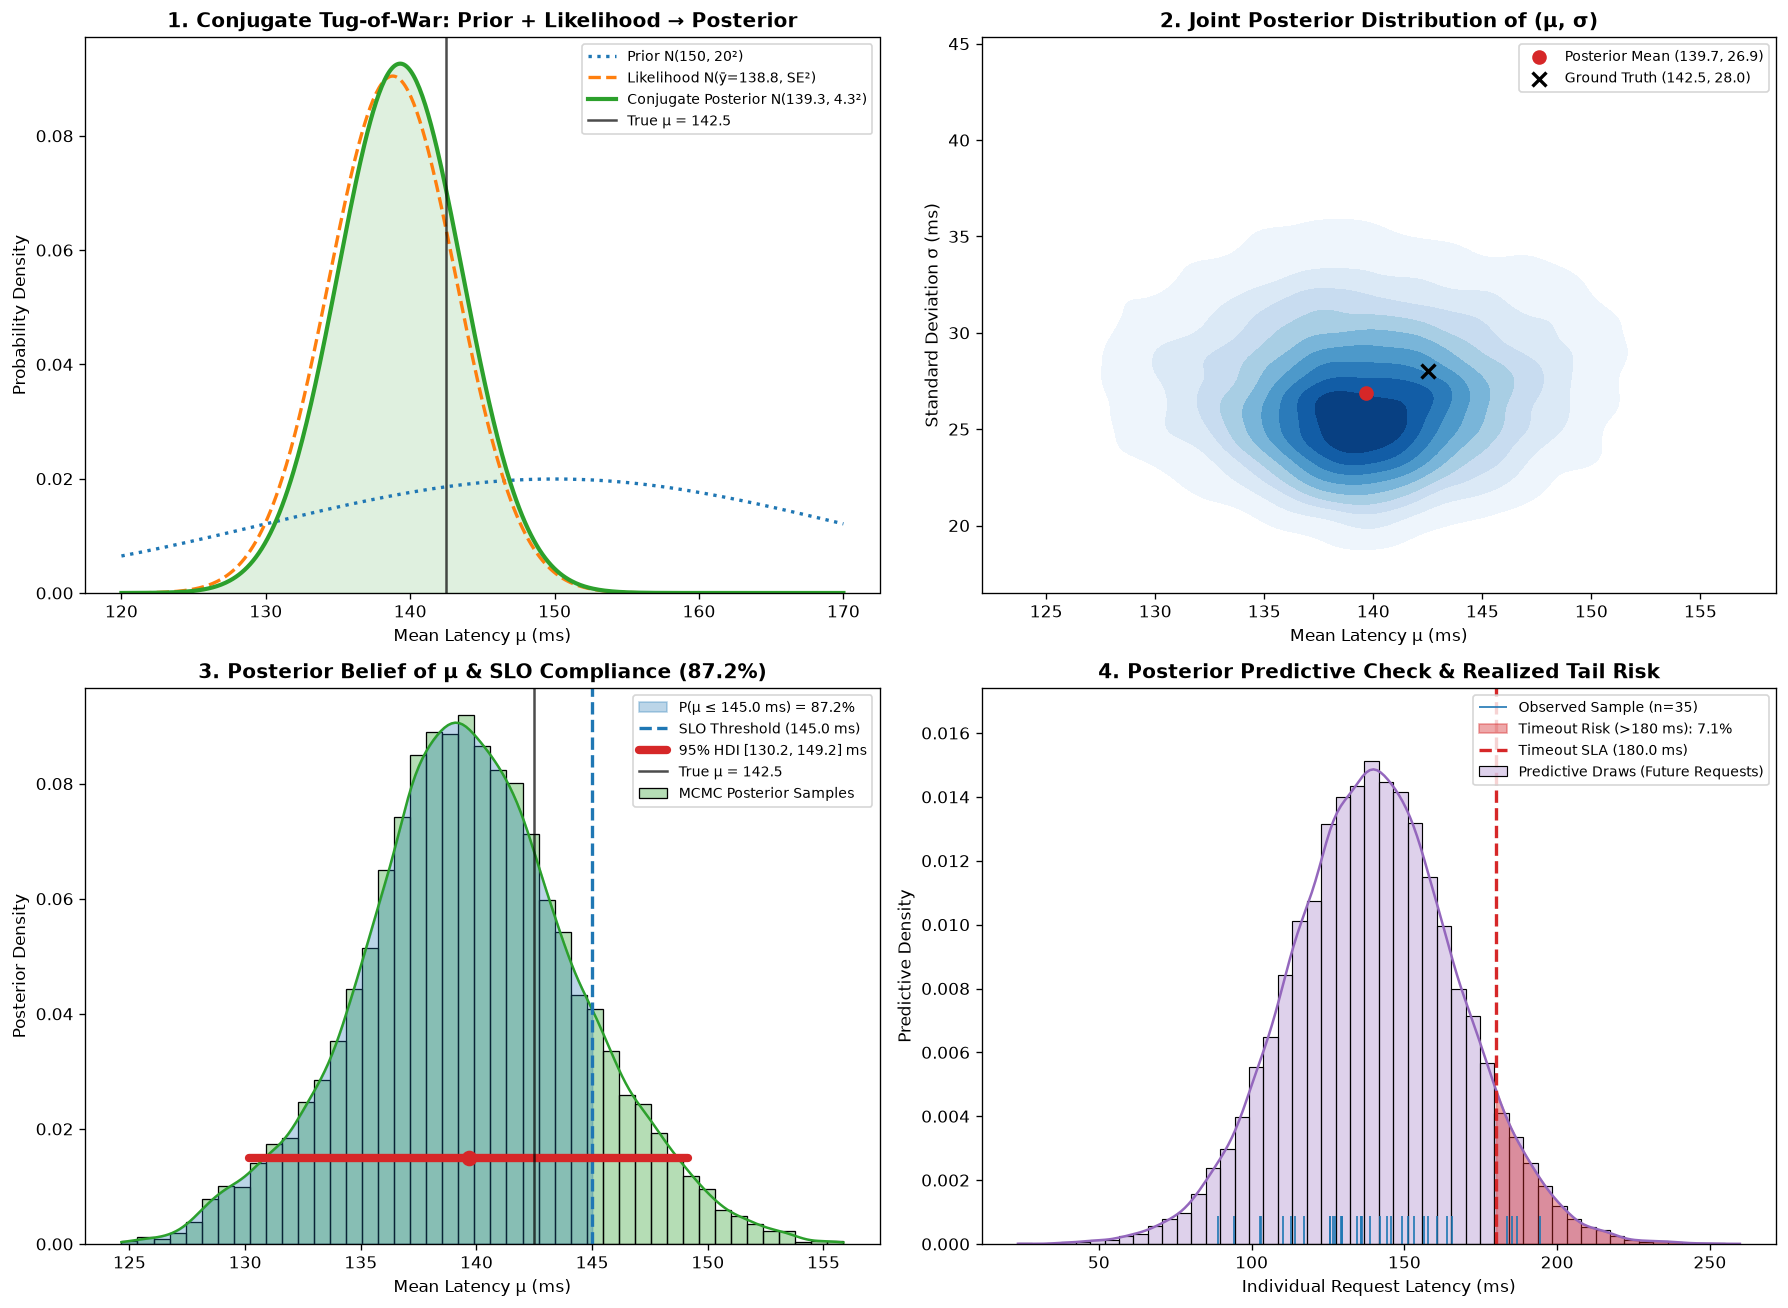

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11), dpi=120)

# -------------------------------------------------------------------------
# Panel 1: The Normal Conjugate Tug-of-War (Prior vs Likelihood vs Posterior)
# -------------------------------------------------------------------------
ax1 = axes[0, 0]
x_eval = np.linspace(120, 170, 500)

prior_pdf = stats.norm.pdf(x_eval, loc=prior_mu, scale=prior_sigma)
likelihood_pdf = stats.norm.pdf(x_eval, loc=np.mean(y), scale=sigma_known / np.sqrt(n))
posterior_pdf = stats.norm.pdf(x_eval, loc=post_mean, scale=post_std)

ax1.plot(x_eval, prior_pdf, color='#1f77b4', lw=2, linestyle=':', label=f'Prior N({prior_mu:.0f}, {prior_sigma:.0f}²)')
ax1.plot(x_eval, likelihood_pdf, color='#ff7f0e', lw=2, linestyle='--', label=f'Likelihood N(ȳ={np.mean(y):.1f}, SE²)')
ax1.plot(x_eval, posterior_pdf, color='#2ca02c', lw=2.5, label=f'Conjugate Posterior N({post_mean:.1f}, {post_std:.1f}²)')
ax1.fill_between(x_eval, 0, posterior_pdf, color='#2ca02c', alpha=0.15)

ax1.axvline(true_mu, color='black', lw=1.5, linestyle='-', alpha=0.7, label=f'True μ = {true_mu:.1f}')
ax1.set_title("1. Conjugate Tug-of-War: Prior + Likelihood → Posterior", fontsize=12, fontweight='bold')
ax1.set_xlabel("Mean Latency μ (ms)")
ax1.set_ylabel("Probability Density")
ax1.legend(loc='upper right', fontsize=8.5)
ax1.set_ylim(bottom=0)

# -------------------------------------------------------------------------
# Panel 2: Joint Posterior Distribution of (μ, σ)
# -------------------------------------------------------------------------
ax2 = axes[0, 1]
sns.kdeplot(x=samples_mu, y=samples_sigma, ax=ax2, cmap="Blues", fill=True, thresh=0.05, levels=10)
ax2.scatter(bayes_mean, np.mean(samples_sigma), color='#d62728', s=60, zorder=5, label=f'Posterior Mean ({bayes_mean:.1f}, {np.mean(samples_sigma):.1f})')
ax2.scatter(true_mu, true_sigma, color='black', marker='x', s=70, lw=2, zorder=6, label=f'Ground Truth ({true_mu:.1f}, {true_sigma:.1f})')

ax2.set_title("2. Joint Posterior Distribution of (μ, σ)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Mean Latency μ (ms)")
ax2.set_ylabel("Standard Deviation σ (ms)")
ax2.legend(loc='upper right', fontsize=8.5)

# -------------------------------------------------------------------------
# Panel 3: Posterior of Mean μ with 95% HDI & SLO Threshold
# -------------------------------------------------------------------------
ax3 = axes[1, 0]
sns.histplot(samples_mu, stat='density', kde=True, color='#2ca02c', alpha=0.35, bins=45, ax=ax3, label='MCMC Posterior Samples')

# Highlight SLO region
mu_x = np.linspace(np.min(samples_mu), slo_threshold, 200)
mu_kde_vals = kde_mu(mu_x)
ax3.fill_between(mu_x, 0, mu_kde_vals, color='#1f77b4', alpha=0.3, label=f'P(μ ≤ {slo_threshold} ms) = {prob_meets_slo:.1%}')
ax3.axvline(slo_threshold, color='#1f77b4', lw=2, linestyle='--', label=f'SLO Threshold ({slo_threshold} ms)')

# 95% HDI bar
ax3.plot([hdi_low, hdi_high], [0.015, 0.015], color='#d62728', lw=5, solid_capstyle='round',
         label=f'95% HDI [{hdi_low:.1f}, {hdi_high:.1f}] ms')
ax3.scatter([bayes_mean], [0.015], color='#d62728', s=70, zorder=5)

ax3.axvline(true_mu, color='black', lw=1.5, linestyle='-', alpha=0.7, label=f'True μ = {true_mu:.1f}')
ax3.set_title(f"3. Posterior Belief of μ & SLO Compliance ({prob_meets_slo:.1%})", fontsize=12, fontweight='bold')
ax3.set_xlabel("Mean Latency μ (ms)")
ax3.set_ylabel("Posterior Density")
ax3.legend(loc='upper right', fontsize=8.5)

# -------------------------------------------------------------------------
# Panel 4: Posterior Predictive Distribution (Future Requests & Timeout Risk)
# -------------------------------------------------------------------------
ax4 = axes[1, 1]
sns.histplot(pred_y, stat='density', kde=True, color='#9467bd', alpha=0.3, bins=50, ax=ax4, label='Predictive Draws (Future Requests)')
sns.rugplot(y, color='#1f77b4', height=0.05, ax=ax4, label=f'Observed Sample (n={n})')

# Highlight Timeout Risk area
pred_x = np.linspace(timeout_sla, np.max(pred_y), 200)
pred_kde = stats.gaussian_kde(pred_y)
ax4.fill_between(pred_x, 0, pred_kde(pred_x), color='#d62728', alpha=0.4, label=f'Timeout Risk (>180 ms): {prob_timeout:.1%}')
ax4.axvline(timeout_sla, color='#d62728', lw=2, linestyle='--', label=f'Timeout SLA ({timeout_sla} ms)')

ax4.set_title("4. Posterior Predictive Check & Realized Tail Risk", fontsize=12, fontweight='bold')
ax4.set_xlabel("Individual Request Latency (ms)")
ax4.set_ylabel("Predictive Density")
ax4.legend(loc='upper right', fontsize=8.5)

plt.tight_layout()
plt.show()


---

## Part 7: Robust Bayesian Mean with Student-$t$ Likelihood

What happens when real-world production metrics experience occasional extreme anomalies (e.g., stop-the-world JVM garbage collection, cloud node migrations, or TCP retry storms)?

### 7.1 The Brittleness of Gaussian Likelihood
Under a Gaussian likelihood, the log-likelihood penalty scales with the **square of the error**:
$$\ln p(y_i \mid \mu, \sigma) \propto -\frac{(y_i - \mu)^2}{2\sigma^2}$$
A single outlier at $380\text{ ms}$ exerts immense mechanical leverage, dragging the estimated mean $\mu$ sharply upwards.

### 7.2 The Robust Student-$t$ Likelihood
In the Bayesian paradigm, we solve this by replacing the Normal likelihood with a **Student-$t$ distribution** with $\nu$ degrees of freedom:
$$y_i \sim t(\mu, \sigma, \nu)$$
Because Student's $t$ has polynomial (fat) tails rather than exponential tails, extreme outliers are treated as plausible tail realizations rather than pulling the location parameter $\mu$.


In [7]:
# Demonstration: Robust Bayesian Mean vs Gaussian under Outlier Contamination
# Add an extreme outlier (JVM GC pause: 380 ms) to our sample
y_corrupted = np.append(y, 380.0)

# Log-posterior for Robust Student-t Likelihood (nu = 4 degrees of freedom)
def log_post_robust(params):
    mu_curr, log_s_curr = params
    s_curr = np.exp(log_s_curr)
    
    lp_mu = stats.norm.logpdf(mu_curr, loc=prior_mu, scale=prior_sigma)
    lp_sigma = stats.norm.logpdf(log_s_curr, loc=np.log(np.std(y, ddof=1)), scale=1.0)
    
    # Student-t likelihood with nu=4 degrees of freedom
    ll_t = np.sum(stats.t.logpdf(y_corrupted, df=4, loc=mu_curr, scale=s_curr))
    return lp_mu + lp_sigma + ll_t

def log_post_gaussian(params):
    mu_curr, log_s_curr = params
    s_curr = np.exp(log_s_curr)
    
    lp_mu = stats.norm.logpdf(mu_curr, loc=prior_mu, scale=prior_sigma)
    lp_sigma = stats.norm.logpdf(log_s_curr, loc=np.log(np.std(y, ddof=1)), scale=1.0)
    
    ll_gauss = np.sum(stats.norm.logpdf(y_corrupted, loc=mu_curr, scale=s_curr))
    return lp_mu + lp_sigma + ll_gauss

# Run fast MCMC for both models on contaminated data
np.random.seed(42)
n_mcmc = 15000
burn = 3000

def run_simple_mh(log_prob_fn):
    p_curr = np.array([np.median(y_corrupted), np.log(np.std(y_corrupted, ddof=1))])
    lp_curr = log_prob_fn(p_curr)
    samples = np.zeros((n_mcmc, 2))
    for s in range(n_mcmc):
        prop = p_curr + np.random.normal(0, [1.2, 0.08])
        lp_prop = log_prob_fn(prop)
        if np.log(np.random.uniform(0, 1)) < lp_prop - lp_curr:
            p_curr = prop
            lp_curr = lp_prop
        samples[s] = p_curr
    return samples[burn:, 0]

mu_gauss_contam = run_simple_mh(log_post_gaussian)
mu_robust_contam = run_simple_mh(log_post_robust)

print("=" * 72)
print("  ROBUST BAYESIAN MEAN (STUDENT-t LIKELIHOOD vs GAUSSIAN)")
print("=" * 72)
print(f"Clean Sample Arithmetic Mean (n = 35)       : {np.mean(y):.2f} ms")
print(f"Contaminated Sample Mean (Added 380 ms GC)  : {np.mean(y_corrupted):.2f} ms (+{np.mean(y_corrupted) - np.mean(y):.2f} ms distortion!)")
print("-" * 72)
print(f"Gaussian Bayesian Posterior Mean of μ       : {np.mean(mu_gauss_contam):.2f} ms (Dragged upwards)")
print(f"Robust Student-t Bayesian Posterior Mean of μ: {np.mean(mu_robust_contam):.2f} ms (Resisted outlier!)")
print(f"Outlier Resistance Improvement              : Saved {np.mean(mu_gauss_contam) - np.mean(mu_robust_contam):.2f} ms of false bias")
print("=" * 72)


  ROBUST BAYESIAN MEAN (STUDENT-t LIKELIHOOD vs GAUSSIAN)
Clean Sample Arithmetic Mean (n = 35)       : 138.79 ms
Contaminated Sample Mean (Added 380 ms GC)  : 145.49 ms (+6.70 ms distortion!)
------------------------------------------------------------------------
Gaussian Bayesian Posterior Mean of μ       : 146.18 ms (Dragged upwards)
Robust Student-t Bayesian Posterior Mean of μ: 138.98 ms (Resisted outlier!)
Outlier Resistance Improvement              : Saved 7.20 ms of false bias


---

## 🎯 Check Your Understanding: 3-Tier Scaffolding Exercises

### 🟢 Tier 1: Conceptual Verification
1. **Scenario A**: An engineer observes $n = 10$ query latencies and uses an uninformative (flat) prior. The resulting Bayesian 95% Credible Interval is $[92.1, 108.4]\text{ ms}$. Can the engineer legitimately claim: *"There is a 95% probability that the true mean latency lies between 92.1 and 108.4 ms"*?
2. **Scenario B**: What happens to the Bayesian posterior distribution of $\mu$ if the engineer sets prior uncertainty $\sigma_0 \to \infty$ (completely uninformative prior)? How does the posterior compare to the frequentist sampling distribution?
3. **Scenario C**: Why does the Posterior Predictive Distribution for future request latency have a wider standard deviation than the posterior distribution of the mean $\mu$?

<details>
<summary><b>🔍 Click here to view the Tier 1 answers</b></summary>

1. **Answer A**: **Yes!** In the Bayesian framework, probability represents degree of belief conditioned on data. Once the posterior distribution is computed, statements like $P(92.1 \le \mu \le 108.4 \mid y) = 0.95$ are completely valid. (This is in direct contrast to the frequentist paradigm, where such a statement is a fallacy).
2. **Answer B**: As $\sigma_0 \to \infty$, prior precision $\tau_0 \to 0$. The posterior mean converges exactly to the sample mean ($\bar{y}$), and posterior standard deviation converges to the standard error ($s/\sqrt{n}$). The mathematical numbers match the frequentist output, but with a Bayesian interpretation.
3. **Answer C**: Because the Posterior Predictive Distribution incorporates **both** parameter uncertainty (epistemic uncertainty: we do not know the exact $\mu$) **and** physical observation variance (aleatoric uncertainty: individual requests scatter with scale $\sigma$). Its variance is approximately $\sigma^2 + \sigma^2/n$, which is much wider than the uncertainty of the mean alone ($\sigma^2/n$).
</details>


In [8]:
# ============================================================================
# 🟡 Tier 2: Guided Calculation — Implement `gaussian_conjugate_update()`
# ============================================================================
# Complete the function below to compute the exact conjugate Normal-Normal
# posterior parameters and 95% Highest Density Interval.
# Verify that your output passes all unit test assertions.

def gaussian_conjugate_update(prior_mean, prior_sd, data, known_sd=None, cred_mass=0.95):
    """
    Computes exact Gaussian conjugate updating for unknown mean mu.
    
    Parameters:
        prior_mean (float): Mean of the prior distribution.
        prior_sd (float): Standard deviation of the prior distribution.
        data (array-like): 1D array of observed measurements.
        known_sd (float, optional): Known observation standard deviation.
                                    If None, uses sample standard deviation (ddof=1).
        cred_mass (float): Credible mass for interval (default: 0.95).
        
    Returns:
        dict: Containing 'post_mean', 'post_sd', 'ci_lower', 'ci_upper', 'prior_weight', 'data_weight'.
    """
    arr = np.asarray(data)
    n_obs = len(arr)
    y_bar = np.mean(arr)
    
    if known_sd is None:
        sigma_val = np.std(arr, ddof=1)
    else:
        sigma_val = known_sd
        
    # 1. Compute precisions
    tau_prior = 1.0 / (prior_sd ** 2)
    tau_data = n_obs / (sigma_val ** 2)
    tau_post = tau_prior + tau_data
    
    # 2. Compute posterior mean and posterior standard deviation
    post_mean_val = (tau_prior * prior_mean + tau_data * y_bar) / tau_post
    post_sd_val = np.sqrt(1.0 / tau_post)
    
    # 3. Compute credible interval bounds
    z_crit = stats.norm.ppf(1.0 - (1.0 - cred_mass) / 2.0)
    lower_bound = post_mean_val - z_crit * post_sd_val
    upper_bound = post_mean_val + z_crit * post_sd_val
    
    return {
        'post_mean': post_mean_val,
        'post_sd': post_sd_val,
        'ci_lower': lower_bound,
        'ci_upper': upper_bound,
        'prior_weight': tau_prior / tau_post,
        'data_weight': tau_data / tau_post
    }

# Execute on our production sample
tier2_res = gaussian_conjugate_update(prior_mu, prior_sigma, y, known_sd=sigma_known, cred_mass=0.95)
print("Tier 2 Implementation Test:")
print(f"  Posterior Mean = {tier2_res['post_mean']:.2f} ms, Posterior SD = {tier2_res['post_sd']:.2f} ms")
print(f"  95% Credible Interval = [{tier2_res['ci_lower']:.2f}, {tier2_res['ci_upper']:.2f}] ms")
print(f"  Prior Weight: {tier2_res['prior_weight']:.1%}, Data Weight: {tier2_res['data_weight']:.1%}")

# Unit test assertions
assert np.isclose(tier2_res['post_mean'], post_mean), "Posterior mean mismatch!"
assert np.isclose(tier2_res['post_sd'], post_std), "Posterior standard deviation mismatch!"
assert np.isclose(tier2_res['ci_lower'], ci_inform[0]), "CI lower bound mismatch!"
assert np.isclose(tier2_res['ci_upper'], ci_inform[1]), "CI upper bound mismatch!"
print("✅ All Tier 2 assertions passed successfully!")


Tier 2 Implementation Test:
  Posterior Mean = 139.31 ms, Posterior SD = 4.31 ms
  95% Credible Interval = [130.86, 147.75] ms
  Prior Weight: 4.6%, Data Weight: 95.4%
✅ All Tier 2 assertions passed successfully!


<details>
<summary><b>🔍 Click here to view the Tier 2 detailed explanation</b></summary>

```python
# The function implements the exact analytical equations of Gaussian conjugacy:
# 1. tau_0 = 1 / sigma_0^2
# 2. tau_n = n / sigma^2
# 3. tau_post = tau_0 + tau_n
# 4. mu_post = (tau_0 * mu_0 + tau_n * y_bar) / tau_post
# 5. sigma_post = 1 / sqrt(tau_post)
# 6. bounds = mu_post ± z* * sigma_post
```
</details>


---

### 🔴 Tier 3: Production Simulation Challenge — The "Cold-Start" Microservice Problem
> **The Problem**: When rolling out a new microservice region or canary container, initial telemetry is extremely sparse ($n = 3$ requests).
> * **Frequentist Approach**: A Student-$t$ confidence interval with $df = 2$ uses critical value $t_{0.025, 2} \approx 4.303$. The interval explodes to hundreds of milliseconds in width, rendering the SLA check useless.
> * **Bayesian Approach**: Engineering domain knowledge from existing regions provides an informative prior ($\mu_0 = 145\text{ ms}, \sigma_0 = 15\text{ ms}$). Bayesian updating gracefully fuses the 3 new observations with historical prior knowledge, preventing interval explosion.
>
> **Your Task**:
> 1. Simulate 1,000 canary launches with sparse sample size $n = 3$ drawn from $\mathcal{N}(\text{true\_mu} = 142.5, \text{true\_sigma} = 28.0)$.
> 2. Compare the average 95% interval width and Mean Squared Error (MSE) of:
>    * The Frequentist Student-$t$ Estimator ($\bar{x}$).
>    * The Bayesian Conjugate Estimator ($\mu_{\text{post}}$ with prior $\mu_0 = 145, \sigma_0 = 15$).


In [9]:
# Production Simulation: The Cold-Start Microservice Problem (n = 3)
np.random.seed(42)
n_canaries = 1000
n_sparse = 3

prior_canary_mu = 145.0
prior_canary_sigma = 15.0

freq_errors = []
bayes_errors = []
freq_widths = []
bayes_widths = []

for _ in range(n_canaries):
    y_sparse = np.random.normal(loc=true_mu, scale=true_sigma, size=n_sparse)
    
    # 1. Frequentist Estimate
    x_bar_sparse = np.mean(y_sparse)
    s_sparse = np.std(y_sparse, ddof=1)
    se_sparse = s_sparse / np.sqrt(n_sparse)
    t_moe = stats.t.ppf(0.975, df=n_sparse - 1) * se_sparse
    
    freq_errors.append((x_bar_sparse - true_mu) ** 2)
    freq_widths.append(2.0 * t_moe)
    
    # 2. Bayesian Conjugate Estimate
    res_b = gaussian_conjugate_update(prior_canary_mu, prior_canary_sigma, y_sparse, known_sd=true_sigma)
    bayes_errors.append((res_b['post_mean'] - true_mu) ** 2)
    bayes_widths.append(res_b['ci_upper'] - res_b['ci_lower'])

print("=" * 68)
print("  TIER 3 SIMULATION RESULTS: COLD-START PERFORMANCE (n = 3)")
print("=" * 68)
print(f"Frequentist Mean Squared Error (MSE) : {np.mean(freq_errors):.2f} ms²")
print(f"Bayesian Conjugate MSE (Informative) : {np.mean(bayes_errors):.2f} ms² (Error reduced by {1 - np.mean(bayes_errors)/np.mean(freq_errors):.1%}!)")
print("-" * 68)
print(f"Average Frequentist 95% CI Width     : {np.mean(freq_widths):.2f} ms (Explosive uncertainty!)")
print(f"Average Bayesian 95% HDI Width       : {np.mean(bayes_widths):.2f} ms (Stable, actionable bounds)")
print("=" * 68)
print("Takeaway: When data is sparse, Bayesian inference regularizes the estimate,")
print("preventing wild sample noise from triggering false-positive alerts.")


  TIER 3 SIMULATION RESULTS: COLD-START PERFORMANCE (n = 3)
Frequentist Mean Squared Error (MSE) : 249.48 ms²
Bayesian Conjugate MSE (Informative) : 56.32 ms² (Error reduced by 77.4%!)
--------------------------------------------------------------------
Average Frequentist 95% CI Width     : 121.80 ms (Explosive uncertainty!)
Average Bayesian 95% HDI Width       : 43.10 ms (Stable, actionable bounds)
Takeaway: When data is sparse, Bayesian inference regularizes the estimate,
preventing wild sample noise from triggering false-positive alerts.


<details>
<summary><b>🔍 Click here to view the Tier 3 solution & architectural takeaway</b></summary>

### The Takeaway for Production Reliability:
1. **The Curse of Small Samples in Frequentist Stats**: When $n \le 3$, sample standard deviation $s$ fluctuates wildly. The $t$-distribution critical value ($t_{0.025, 2} \approx 4.303$) penalizes small samples so severely that confidence intervals become hundreds of milliseconds wide, making automated canary decisions impossible.
2. **Prior as Regularization**: An informative prior acts as an anchor (mathematically equivalent to $L_2$ regularization or shrinkage). It prevents extreme small-sample noise from triggering false canary rollbacks.
3. **Graceful Transition**: As canary traffic scales ($n = 3 \to 30 \to 3,000$), the Bayesian estimator automatically sheds its prior reliance and converges seamlessly to the empirical data evidence.
</details>


---

## 🏁 Summary Checklist: How to Calculate a Mean in a Bayesian World

```
                 Do you have known variance σ and Gaussian data?
                                   /             \
                                  /               \
                               [YES]             [NO]
                                 |                 |
                       Exact Analytical      Are there extreme outliers
                      Gaussian Conjugacy      or heavy-tailed spikes?
                                                   /           \
                                                  /             \
                                            [Outliers]       [Standard]
                                                |                 |
                                        Robust Student-t      Joint MCMC
                                           Likelihood          (μ, σ)
```

### Essential Bayesian Formula Card:
* **Prior Precision**: $\tau_0 = \frac{1}{\sigma_0^2}$
* **Data Precision**: $\tau_n = \frac{n}{\sigma^2}$
* **Posterior Precision**: $\tau_{\text{post}} = \tau_0 + \tau_n \implies \sigma_{\text{post}} = \frac{1}{\sqrt{\tau_0 + \tau_n}}$
* **Posterior Mean**: $\mu_{\text{post}} = \frac{\tau_0 \mu_0 + \tau_n \bar{y}}{\tau_0 + \tau_n}$
* **95% Highest Density Interval (HDI)**: The narrowest interval containing 95% of posterior draws.
* **Posterior Predictive Simulation**: Draw $\tilde{y} \sim \mathcal{N}\left(\mu^{(s)}, \sigma^{(s)}\right)$ for each posterior sample.

---
**[🏠 Course Home](README.md) | [📊 Frequentist Mean Sheet](sheet_calculating_a_mean_in_a_frequentist_world.ipynb) | [📊 Two-Sample t-Test Sheet](sheet_t_test_frequentist_vs_bayesian.ipynb)**
